# 04: Final Comparison: Tables and Figures for the Report

**Why this notebook:** notebooks 01–03 each answered one question. This one collects all results from `results/results.csv` into the tables and figures the report needs. It makes **no LLM calls** and runs in seconds, so rerun it whenever new results are added (e.g. a new dataset or model). Everything updates automatically.

**What it produces** (saved in `results/tables/` and `results/figures/`):
1. **Main comparison:** paper (GPT-3.5) vs K-means vs our baseline vs our method.
2. **Ablation:** the effect of each fix (A+B, C, D) per model.
3. **Gap recovered:** how much of the gap to GPT-3.5 our fixes close.
4. **Number of clusters:** found vs true.
5. **Threshold sensitivity** (Qwen 2.5).
6. **Practical comparison:** LLM calls, time, hardware, privacy.

**Extra variants (shown as extra rows when they exist for a dataset and model):**
- **E** (notebook 05): the LLM classifies only a representative 10% of the texts, and a local classifier labels the rest (84% fewer LLM calls).
- **F** (notebook 07): every label comes with an LLM-written definition and keywords.
- **E+F** (notebook 05): definitions, with the LLM on a representative 20% and the classifier on the rest.

**Reported configuration** ("Ours" = merge + rescue, A+B+C), with the threshold chosen in notebook 02 by reading the label groups:
- Massive-D: Qwen 2.5 7B at 0.5, Qwen3 8B at 0.6
- Massive-I: Qwen 2.5 7B at 0.4

When you run a new dataset or model, add its chosen threshold to `CHOSEN` in the setup cell.

## 0. Setup and reference numbers from the paper
The paper's numbers (GPT-3.5 method and K-means with E5) are copied from its main results table and cluster-count table. Scores are converted to 0–1, like ours.

In [19]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("./results/tables", exist_ok=True)
os.makedirs("./results/figures", exist_ok=True)

NAMES = {"arxiv_fine": "ArxivS2S", "go_emotion": "GoEmo", "massive_intent": "Massive-I",
         "massive_scenario": "Massive-D", "mtop_intent": "MTOP-I"}
TRUE_K = {"arxiv_fine": 93, "go_emotion": 27, "massive_intent": 59, "massive_scenario": 18, "mtop_intent": 102}
# Paper, main table: (ACC, NMI, ARI) in %, and number of clusters found by the GPT-3.5 method
PAPER_GPT = {"arxiv_fine": (38.78, 57.43, 20.55), "go_emotion": (31.66, 27.39, 13.50),
             "massive_intent": (71.75, 78.00, 56.86), "massive_scenario": (64.12, 65.44, 48.92),
             "mtop_intent": (72.18, 78.78, 71.93)}
PAPER_GPT_K = {"arxiv_fine": 122, "go_emotion": 56, "massive_intent": 71, "massive_scenario": 24, "mtop_intent": 83}
PAPER_KMEANS = {"arxiv_fine": (31.21, 54.47, 17.01), "go_emotion": (22.14, 21.26, 9.64),
                "massive_intent": (52.79, 70.76, 39.03), "massive_scenario": (62.21, 65.42, 47.69),
                "mtop_intent": (34.48, 71.47, 26.35)}

MODELS = {"qwen2.5:7b": "Qwen 2.5 7B", "qwen3:8b": "Qwen3 8B", "llama3.1:8b": "Llama 3.1 8B"}
# Threshold chosen in notebook 02 by reading the label groups, per (dataset, model)
CHOSEN = {("massive_scenario", "qwen2.5:7b"): 0.5, ("massive_scenario", "qwen3:8b"): 0.6,
          ("massive_intent", "qwen2.5:7b"): 0.4}
def chosen_t(d, m):
    return CHOSEN.get((d, m), -1)   # -1 matches no row: model not run on this dataset
OURS = "A+B+C (merge + rescue)"
E_METHOD = "E (A+B+C, LLM on 10% + classifier)"   # cost-reduced variant from notebook 05
F_METHOD = "F (A+B+C + label definitions)"         # label definitions, notebook 07
EF_METHOD = "E+F (definitions, LLM on 50% + classifier)"   # definitions + cost reduction, notebook 05
# Extra variants shown as rows after "Ours": (table name, method)
EXTRA = [("Ours + E (LLM on 10%)", E_METHOD), ("Ours + F (definitions)", F_METHOD), ("Ours + E+F (definitions, LLM on 50%)", EF_METHOD)]
# Known timing fix: the Qwen 2.5 t=0.5 rows were rerun from saved answers (time 0.0); the real classification time was 9.5 min
TIME_FIX = {("massive_scenario", "qwen2.5:7b", 0.5): 9.5}

res = pd.read_csv("./results/results.csv")
for col in ["threshold", "rescue_sim", "min_size"]:
    if col not in res.columns:
        res[col] = np.nan
for (d, m, t), v in TIME_FIX.items():
    res.loc[(res.dataset == d) & (res.model == m) & (res.threshold == t), "time_min"] = v
# The Qwen3 baseline row stores label generation + classification (11.4 + 119.2 min); keep classification only, like the others
res.loc[(res.dataset == "massive_scenario") & (res.model == "qwen3:8b") & (res.method == "baseline"), "time_min"] = 119.2
res.loc[(res.dataset == "massive_intent") & (res.model == "qwen2.5:7b") & (res.method == "baseline"), "time_min"] = 10.1   # classification only

DATASETS = [d for d in NAMES if d in set(res.dataset)]
print("Datasets with results:", [NAMES[d] for d in DATASETS])
print("Models with results:", sorted(set(res.model) - {"none"}))

def save_table(df, name):
    df.to_csv(f"./results/tables/{name}.csv", index=False)
    try:
        df.to_latex(f"./results/tables/{name}.tex", index=False, float_format="%.1f")
    except Exception as e:
        print("LaTeX export skipped:", e)

def pct(x):
    return round(100 * float(x), 1)

Datasets with results: ['Massive-I', 'Massive-D']
Models with results: ['qwen2.5:7b', 'qwen3:8b']


## 1. Main comparison
For each dataset: the paper's GPT-3.5 result, K-means (paper and ours), and our baseline and improved method for each local model. Scores in %, as in the paper.

The **"K known?"** column matters: K-means with the true K uses information that our method never gets.

In [20]:
def main_table(d):
    rows = []
    g = PAPER_GPT[d]; k = PAPER_KMEANS[d]
    rows.append({"Method": "GPT-3.5 method (paper)", "K known?": "no", "Clusters": PAPER_GPT_K[d], "ACC": g[0], "NMI": g[1], "ARI": g[2]})
    rows.append({"Method": "K-means E5, true K (paper)", "K known?": "yes", "Clusters": TRUE_K[d], "ACC": k[0], "NMI": k[1], "ARI": k[2]})
    r = res[(res.dataset == d) & (res.model == "none")]
    for label, method in [("K-means E5-large, true K (ours)", "K-means (E5-large, true K)"),
                          ("K-means E5-large, silhouette K (ours)", "K-means (E5-large, K chosen by silhouette)")]:
        x = r[r.method == method]
        if len(x):
            x = x.iloc[-1]
            rows.append({"Method": label, "K known?": "yes" if "true K" in label else "no",
                         "Clusters": int(x.predicted_clusters), "ACC": pct(x.ACC), "NMI": pct(x.NMI), "ARI": pct(x.ARI)})
    for m, mname in MODELS.items():
        b = res[(res.dataset == d) & (res.model == m) & (res.method == "baseline")]
        o = res[(res.dataset == d) & (res.model == m) & (res.method == OURS) & (res.threshold == chosen_t(d, m))]
        if len(b):
            b = b.iloc[-1]
            rows.append({"Method": f"Original method, {mname}", "K known?": "no", "Clusters": int(b.predicted_clusters),
                         "ACC": pct(b.ACC), "NMI": pct(b.NMI), "ARI": pct(b.ARI)})
        if len(o):
            o = o.iloc[-1]
            rows.append({"Method": f"Ours, {mname} (t={chosen_t(d, m)})", "K known?": "no", "Clusters": int(o.predicted_clusters),
                         "ACC": pct(o.ACC), "NMI": pct(o.NMI), "ARI": pct(o.ARI)})
        for xname, xmethod in EXTRA:
            e = res[(res.dataset == d) & (res.model == m) & (res.method == xmethod)]
            if len(e):
                e = e.iloc[-1]
                rows.append({"Method": f"{xname}, {mname}", "K known?": "no", "Clusters": int(e.predicted_clusters),
                             "ACC": pct(e.ACC), "NMI": pct(e.NMI), "ARI": pct(e.ARI)})
    t = pd.DataFrame(rows)
    t.insert(2, "True K", TRUE_K[d])
    return t

for d in DATASETS:
    t = main_table(d)
    save_table(t, f"main_{d}")
    print(f"\n=== {NAMES[d]} (true K = {TRUE_K[d]}) ===")
    display(t)


=== Massive-I (true K = 59) ===


,Method,K known?,True K,Clusters,ACC,NMI,ARI
0,GPT-3.5 method (paper),no,59,71,71.75,78.00,56.86
1,"K-means E5, true K (paper)",yes,59,59,52.79,70.76,39.03
2,"K-means E5-large, true K (ours)",yes,59,59,52.60,71.00,38.90
3,"K-means E5-large, silhouette K (ours)",no,59,35,52.20,69.20,42.10
4,"Original method, Qwen 2.5 7B",no,59,92,33.10,51.40,7.40
5,"Ours, Qwen 2.5 7B (t=0.4)",no,59,59,45.80,66.40,37.00
6,"Ours + E (LLM on 10%), Qwen 2.5 7B",no,59,49,44.80,62.40,28.40
7,"Ours + F (definitions), Qwen 2.5 7B",no,59,61,51.80,69.30,36.10
8,"Ours + E+F (definitions, LLM on 50%), Qwen 2.5 7B",no,59,60,52.70,68.80,34.20



=== Massive-D (true K = 18) ===


,Method,K known?,True K,Clusters,ACC,NMI,ARI
0,GPT-3.5 method (paper),no,18,24,64.12,65.44,48.92
1,"K-means E5, true K (paper)",yes,18,18,62.21,65.42,47.69
2,"K-means E5-large, true K (ours)",yes,18,18,60.20,65.30,46.20
3,"K-means E5-large, silhouette K (ours)",no,18,35,47.10,64.90,35.60
4,"Original method, Qwen 2.5 7B",no,18,71,39.90,55.80,32.00
5,"Ours, Qwen 2.5 7B (t=0.5)",no,18,36,49.40,58.90,38.60
6,"Ours + E (LLM on 10%), Qwen 2.5 7B",no,18,33,55.20,62.00,41.60
7,"Original method, Qwen3 8B",no,18,241,30.30,60.90,22.50
8,"Ours, Qwen3 8B (t=0.6)",no,18,93,44.00,62.10,34.90
9,"Ours + E (LLM on 10%), Qwen3 8B",no,18,59,53.80,61.50,37.20


### Main comparison chart

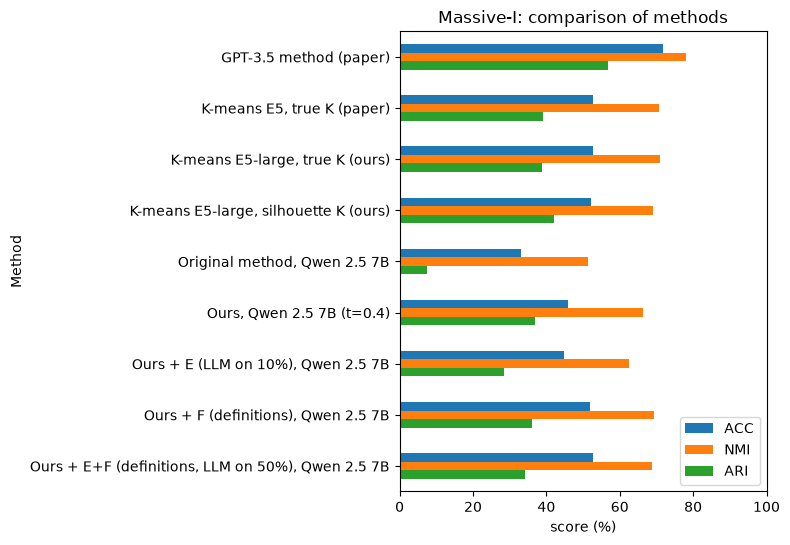

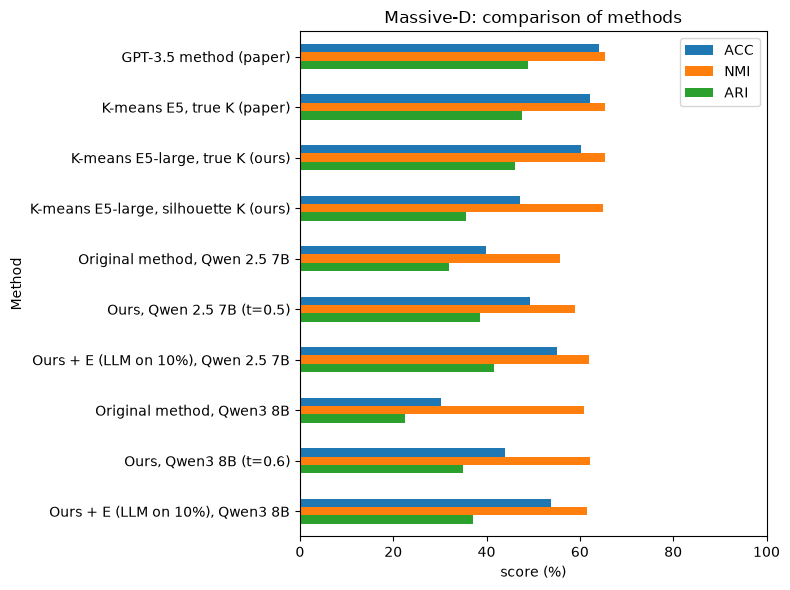

In [21]:
for d in DATASETS:
    t = main_table(d).set_index("Method")[["ACC", "NMI", "ARI"]]
    ax = t.plot.barh(figsize=(8, 0.45 * len(t) + 1.5))
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("score (%)")
    ax.set_title(f"{NAMES[d]}: comparison of methods")
    plt.tight_layout(); plt.savefig(f"./results/figures/main_{d}.png", dpi=200); plt.show()

## 2. Ablation: the effect of each fix
How each fix changes the scores, per model. **A+B** = remove catch-all labels + embedding merge; **C** = rescue failed answers; **D** = discover new clusters from failed answers.

In [22]:
ORDER = ["baseline", "A+B (merge)", "A+B+C (merge + rescue)", "A+B+D (merge + discovery)", E_METHOD, F_METHOD, EF_METHOD]
abl_all = []
for d in DATASETS:
    for m, mname in MODELS.items():
        r = res[(res.dataset == d) & (res.model == m)]
        r = r[(r.method == "baseline") | (r.threshold == chosen_t(d, m)) & r.method.isin(ORDER)]
        if not len(r):
            continue
        r = r.drop_duplicates("method", keep="last").set_index("method").reindex([x for x in ORDER if x in set(r.method)])
        a = pd.DataFrame({"Dataset": NAMES[d], "Model": mname, "Variant": r.index,
                          "Clusters": r.predicted_clusters.astype(int).values,
                          "ACC": (100 * r.ACC).round(1).values, "NMI": (100 * r.NMI).round(1).values,
                          "ARI": (100 * r.ARI).round(1).values, "Failed answers": r.unsuccessful.astype(int).values,
                          "LLM calls": r.llm_calls.astype(int).values})
        abl_all.append(a)
abl = pd.concat(abl_all, ignore_index=True)
save_table(abl, "ablation")
abl

,Dataset,Model,Variant,Clusters,ACC,NMI,ARI,Failed answers,LLM calls
0,Massive-I,Qwen 2.5 7B,baseline,92,33.1,51.4,7.4,1131,3174
1,Massive-I,Qwen 2.5 7B,A+B (merge),51,42.1,61.2,28.0,433,3173
2,Massive-I,Qwen 2.5 7B,A+B+C (merge + rescue),59,45.8,66.4,37.0,0,3173
3,Massive-I,Qwen 2.5 7B,A+B+D (merge + discovery),60,46.3,66.7,37.2,0,3173
4,Massive-I,Qwen 2.5 7B,"E (A+B+C, LLM on 10% + classifier)",49,44.8,62.4,28.4,0,496
5,Massive-I,Qwen 2.5 7B,F (A+B+C + label definitions),61,51.8,69.3,36.1,0,3234
6,Massive-I,Qwen 2.5 7B,"E+F (definitions, LLM on 50% + classifier)",60,52.7,68.8,34.2,0,1747
7,Massive-D,Qwen 2.5 7B,baseline,71,39.9,55.8,32.0,175,3174
8,Massive-D,Qwen 2.5 7B,A+B (merge),37,48.1,57.9,36.4,194,3173
9,Massive-D,Qwen 2.5 7B,A+B+C (merge + rescue),36,49.4,58.9,38.6,0,3173


## 3. Gap recovered
Switching from GPT-3.5 to a small local model loses accuracy. This table shows **how much of that loss our fixes recover**:

`gap recovered = (ours − original method with the local model) / (GPT-3.5 − original method with the local model)`

100% would mean matching GPT-3.5. A negative gap (the local baseline already beats GPT-3.5 on that metric) is shown as "n/a".

In [23]:
gap_rows = []
for d in DATASETS:
    g = dict(zip(["ACC", "NMI", "ARI"], PAPER_GPT[d]))
    for m, mname in MODELS.items():
        b = res[(res.dataset == d) & (res.model == m) & (res.method == "baseline")]
        if not len(b):
            continue
        b = b.iloc[-1]
        for vname, method in [("Ours (A+B+C)", OURS)] + EXTRA:
            o = res[(res.dataset == d) & (res.model == m) & (res.method == method) & (res.threshold == chosen_t(d, m))]
            if not len(o):
                continue
            o = o.iloc[-1]
            row = {"Dataset": NAMES[d], "Model": mname, "Variant": vname}
            for met in ["ACC", "NMI", "ARI"]:
                gap = g[met] - 100 * b[met]
                gain = 100 * (o[met] - b[met])
                row[f"{met} gain (points)"] = round(gain, 1)
                row[f"{met} gap recovered"] = f"{100 * gain / gap:.0f}%" if gap > 0 else "n/a"
            gap_rows.append(row)
gaps = pd.DataFrame(gap_rows)
save_table(gaps, "gap_recovered")
gaps

,Dataset,Model,Variant,ACC gain (points),ACC gap recovered,NMI gain (points),NMI gap recovered,ARI gain (points),ARI gap recovered
0,Massive-I,Qwen 2.5 7B,Ours (A+B+C),12.7,33%,15.0,56%,29.5,60%
1,Massive-I,Qwen 2.5 7B,Ours + E (LLM on 10%),11.7,30%,11.1,42%,21.0,42%
2,Massive-I,Qwen 2.5 7B,Ours + F (definitions),18.7,48%,17.9,67%,28.7,58%
3,Massive-I,Qwen 2.5 7B,"Ours + E+F (definitions, LLM on 50%)",19.6,51%,17.5,66%,26.8,54%
4,Massive-D,Qwen 2.5 7B,Ours (A+B+C),9.5,39%,3.1,32%,6.5,39%
5,Massive-D,Qwen 2.5 7B,Ours + E (LLM on 10%),15.3,63%,6.1,64%,9.5,56%
6,Massive-D,Qwen3 8B,Ours (A+B+C),13.7,41%,1.2,27%,12.4,47%
7,Massive-D,Qwen3 8B,Ours + E (LLM on 10%),23.5,70%,0.6,13%,14.7,56%


## 4. Number of clusters found
The original method over-splits, and this is the main weakness we identified. This chart shows how far each method is from the true number of clusters.

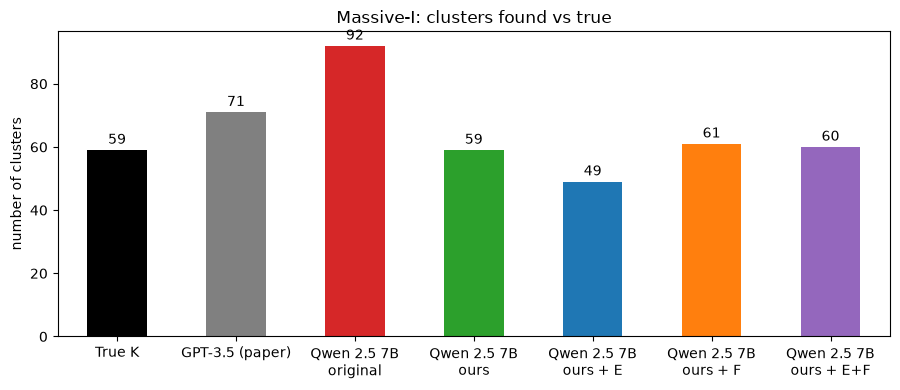

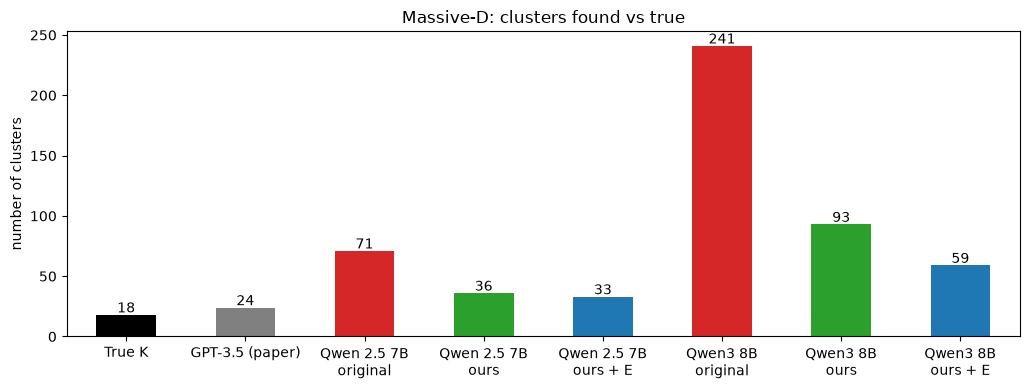

In [24]:
for d in DATASETS:
    bars = {"True K": TRUE_K[d], "GPT-3.5 (paper)": PAPER_GPT_K[d]}
    for m, mname in MODELS.items():
        b = res[(res.dataset == d) & (res.model == m) & (res.method == "baseline")]
        o = res[(res.dataset == d) & (res.model == m) & (res.method == OURS) & (res.threshold == chosen_t(d, m))]
        if len(b): bars[f"{mname}\noriginal"] = int(b.iloc[-1].predicted_clusters)
        if len(o): bars[f"{mname}\nours"] = int(o.iloc[-1].predicted_clusters)
        for xname, xmethod in EXTRA:
            e = res[(res.dataset == d) & (res.model == m) & (res.method == xmethod)]
            if len(e): bars[f"{mname}\n{xname.replace('Ours ', 'ours ').split(' (')[0]}"] = int(e.iloc[-1].predicted_clusters)
    s = pd.Series(bars)
    colors = ["black", "gray"] + ["tab:red" if "original" in k else ("tab:purple" if "+ E+F" in k else "tab:orange" if "+ F" in k
                                   else "tab:blue" if "+ E" in k else "tab:green") for k in list(s.index)[2:]]
    ax = s.plot.bar(color=colors, figsize=(max(8, 1.3 * len(s)), 4), rot=0)
    for i, v in enumerate(s.values):
        ax.text(i, v + 2, str(v), ha="center")
    ax.set_ylabel("number of clusters"); ax.set_title(f"{NAMES[d]}: clusters found vs true")
    plt.tight_layout(); plt.savefig(f"./results/figures/clusters_{d}.png", dpi=200); plt.show()

## 5. Threshold sensitivity (Qwen 2.5)
Same analysis as notebook 02, saved as a figure for the report.

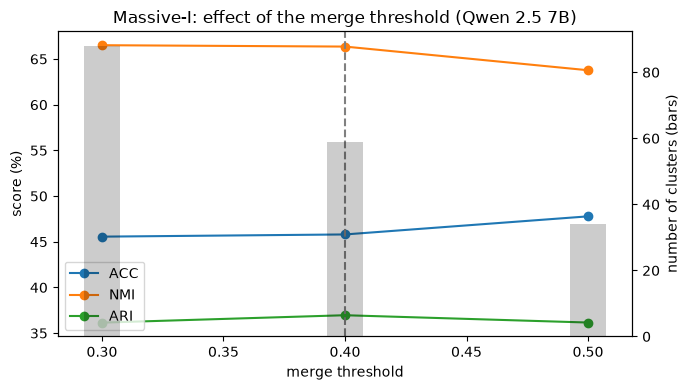

,threshold,predicted_clusters,ACC,NMI,ARI
24,0.3,88,0.4556,0.6651,0.3615
30,0.4,59,0.4580,0.6636,0.3696
27,0.5,34,0.4778,0.6377,0.3616


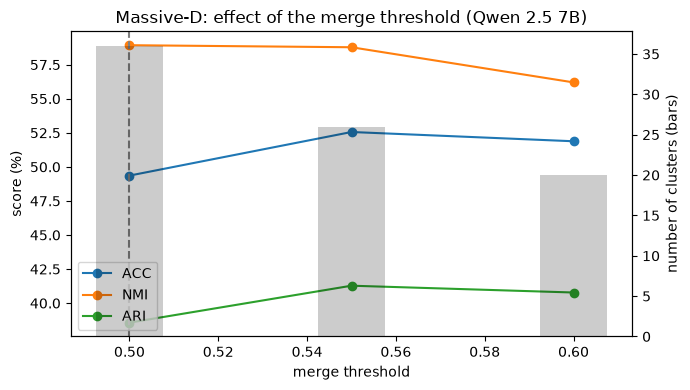

,threshold,predicted_clusters,ACC,NMI,ARI
8,0.50,36,0.4936,0.5893,0.3857
2,0.55,26,0.5256,0.5878,0.4128
5,0.60,20,0.5188,0.5620,0.4078


In [25]:
for d in DATASETS:
    sens = res[(res.dataset == d) & (res.model == "qwen2.5:7b") & (res.method == OURS)].dropna(subset=["threshold"])
    sens = sens.drop_duplicates("threshold", keep="last").sort_values("threshold")
    if len(sens) < 2:
        continue
    fig, ax1 = plt.subplots(figsize=(7, 4))
    for met in ["ACC", "NMI", "ARI"]:
        ax1.plot(sens.threshold, 100 * sens[met], marker="o", label=met)
    ax1.axvline(chosen_t(d, "qwen2.5:7b"), ls="--", c="gray")
    ax1.set_xlabel("merge threshold"); ax1.set_ylabel("score (%)")
    ax2 = ax1.twinx()
    ax2.bar(sens.threshold, sens.predicted_clusters, width=0.015, alpha=0.2, color="black")
    ax2.set_ylabel("number of clusters (bars)")
    ax1.legend(loc="lower left"); plt.title(f"{NAMES[d]}: effect of the merge threshold (Qwen 2.5 7B)")
    plt.tight_layout(); plt.savefig(f"./results/figures/sensitivity_{d}.png", dpi=200); plt.show()
    display(sens[["threshold", "predicted_clusters", "ACC", "NMI", "ARI"]])

## 6. Practical comparison
Scores are not the only reason to choose a method. This table puts the measured cost (LLM calls, time) next to the practical properties that motivate a local model.

GPT-3.5 cost and time come from the paper (Table 7: $3.50 and 3.3 min for 20k texts), scaled to this dataset's size. The local models run on one RTX 4060 (8 GB).

In [26]:
prac = []
for d in DATASETS:
    n = int(res[res.dataset == d].n_texts.iloc[0])
    prac.append({"Dataset": NAMES[d], "Method": "GPT-3.5 method (paper)", "LLM calls": "≈ n/15 + 1 + n",
                 "Classification time": f"≈{3.3 * n / 20000:.1f} min (API, parallel)", "API cost": f"≈${3.5 * n / 20000:.2f}",
                 "Runs offline / private data": "no", "Reproducible": "no (model can change or be retired)"})
    for m, mname in MODELS.items():
        for label, method, t in [("original", "baseline", None), ("ours", OURS, chosen_t(d, m)), ("ours + E, LLM on 10%", E_METHOD, chosen_t(d, m)),
                                 ("ours + F, definitions", F_METHOD, chosen_t(d, m)), ("ours + E+F, LLM on 50%", EF_METHOD, chosen_t(d, m))]:
            r = res[(res.dataset == d) & (res.model == m) & (res.method == method)]
            if t is not None:
                r = r[r.threshold == t]
            if not len(r):
                continue
            r = r.iloc[-1]
            prac.append({"Dataset": NAMES[d], "Method": f"{mname} ({label})", "LLM calls": int(r.llm_calls),
                         "Classification time": f"{r.time_min:.1f} min (RTX 4060)", "API cost": "$0",
                         "Runs offline / private data": "yes", "Reproducible": "yes (fixed local model)"})
    prac.append({"Dataset": NAMES[d], "Method": "K-means E5 (silhouette K)", "LLM calls": 0,
                 "Classification time": "< 1 min (after embeddings)", "API cost": "$0",
                 "Runs offline / private data": "yes", "Reproducible": "yes"})
practical = pd.DataFrame(prac)
save_table(practical, "practical")
practical

,Dataset,Method,LLM calls,Classification time,API cost,Runs offline / private data,Reproducible
0,Massive-I,GPT-3.5 method (paper),≈ n/15 + 1 + n,"≈0.5 min (API, parallel)",≈$0.52,no,no (model can change or be retired)
1,Massive-I,Qwen 2.5 7B (original),3174,10.1 min (RTX 4060),$0,yes,yes (fixed local model)
2,Massive-I,Qwen 2.5 7B (ours),3173,0.0 min (RTX 4060),$0,yes,yes (fixed local model)
3,Massive-I,"Qwen 2.5 7B (ours + E, LLM on 10%)",496,1.1 min (RTX 4060),$0,yes,yes (fixed local model)
4,Massive-I,"Qwen 2.5 7B (ours + F, definitions)",3234,119.0 min (RTX 4060),$0,yes,yes (fixed local model)
5,Massive-I,"Qwen 2.5 7B (ours + E+F, LLM on 50%)",1747,59.5 min (RTX 4060),$0,yes,yes (fixed local model)
6,Massive-I,K-means E5 (silhouette K),0,< 1 min (after embeddings),$0,yes,yes
7,Massive-D,GPT-3.5 method (paper),≈ n/15 + 1 + n,"≈0.5 min (API, parallel)",≈$0.52,no,no (model can change or be retired)
8,Massive-D,Qwen 2.5 7B (original),3174,25.9 min (RTX 4060),$0,yes,yes (fixed local model)
9,Massive-D,Qwen 2.5 7B (ours),3173,9.5 min (RTX 4060),$0,yes,yes (fixed local model)


## Saved files
All tables are in `results/tables/` (CSV, plus LaTeX `.tex` for Overleaf) and all figures in `results/figures/` (PNG, 200 dpi). They are ready to insert into the report.

In [27]:
for folder in ["./results/tables", "./results/figures"]:
    print(folder)
    for f in sorted(os.listdir(folder)):
        print("   ", f)

./results/tables
    ablation.csv
    ablation.tex
    cost_reduction.csv
    gap_recovered.csv
    gap_recovered.tex
    main_massive_intent.csv
    main_massive_intent.tex
    main_massive_scenario.csv
    main_massive_scenario.tex
    outliers_accuracy.csv
    outliers_scores.csv
    practical.csv
    practical.tex
./results/figures
    clusters_massive_intent.png
    clusters_massive_scenario.png
    cost_massive_intent_qwen2.5_7b.png
    cost_massive_intent_qwen2.5_7b_C.png
    cost_massive_intent_qwen2.5_7b_F.png
    cost_massive_scenario_qwen2.5_7b.png
    cost_massive_scenario_qwen2.5_7b_C.png
    cost_massive_scenario_qwen3_8b.png
    cost_massive_scenario_qwen3_8b_C.png
    main_massive_intent.png
    main_massive_scenario.png
    outliers_massive_intent_qwen2.5_7b.png
    outliers_massive_scenario_qwen2.5_7b.png
    outliers_massive_scenario_qwen3_8b.png
    sensitivity_massive_intent.png
    sensitivity_massive_scenario.png


## Key messages for the report (Massive-D)
1. **The original method breaks on small local models.** The LLM merge fails (Qwen 2.5: 71 clusters, Qwen3: 241, true 18), and accuracy drops from 64.1 (GPT-3.5) to 39.9 / 30.3 ACC.
2. **Our fixes work for both models.** ACC rises to 49.4 (Qwen 2.5) and 44.0 (Qwen3), recovering a large part of the gap to GPT-3.5. Qwen3 reaches 62.1 NMI vs 65.4 for GPT-3.5.
3. **The embedding merge (A+B) gives most of the gain.** Rescue (C) adds a little, and discovery (D) adds nothing measurable but reveals missing topics.
4. **Against K-means, when K is unknown,** our method is better on ACC and ARI. K-means only wins when given the true K.
5. **The remaining gap is granularity:** our method still finds 36–93 clusters vs 18 true (GPT-3.5: 24).
6. **Cost (method E, notebook 05):** letting the LLM classify only a representative 10% of the texts and a local classifier label the rest cuts LLM calls by 84% (3,173 → 496) and classification time by about 90%. On Massive-D the scores even rise (Qwen 2.5 ACC 49.4 → 55.2; Qwen3 44.0 → 53.8), partly because small fragmented clusters disappear. On Massive-I about 2–23% of the scores is lost at 10%; 20–30% keeps nearly all of it.
7. **Definitions (F, notebook 07, Massive-I):** ACC 45.8 → 51.8 and NMI 66.4 → 69.3, level with K-means; large gains on intents that differ by one action word (e.g. `iot hue lightup` 0% → 93%), losses where near-duplicate labels split one category (`weather query` 74% → 45%). Classification became 11× slower (119 min), which E+F addresses.
8. **Practical value:** $0 API cost, runs offline on one consumer GPU, keeps data private and gives reproducible results, at the cost of lower accuracy than GPT-3.5 and slower runs than a parallel API.